**Name:** Yasir Alghamdi
**ID:** 2230004157
**Section:** 9MA2
**Lab** : 11


---

# Lab 11: Attention


### Attention is a mechanism that allows a neural network to focus more on relevant information when making a prediction.

Encoder-decoder architecture with attention:
<img src="https://drive.google.com/thumbnail?id=1-QeHdZIeKTo_nAqfh7pRA_o4Nk8CAmP6&sz=w1000" width="700">

## Step 1 — Import libraries

In [5]:
import pandas as pd
import torch
from torch import nn
import matplotlib.pyplot as plt
from google.colab import files

torch.manual_seed(42)

## Step 2 — Upload the dataset

In [6]:
df = pd.read_csv("/content/Lab_11_QnA_Dataset.csv")
print("Number of questions:", len(df))
print("Number of answer groups:", df["answer_id"].nunique())
display(df.head())


Number of questions: 168
Number of answer groups: 12


,question,answer_id,answer
0,Do you get hurt?,0,I don't have a body.
1,Do you have fingers?,0,I don't have a body.
2,Do you ever breathe,0,I don't have a body.
3,Do you masticate?,0,I don't have a body.
4,Can you throw up?,0,I don't have a body.


## Step 3 — Preprocessing

1. Lowercase each question and remove punctuation.
2. Give each word a number.
3. Make all questions the same length by adding zeros (**padding**).

In [7]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

# 1. Lowercase
df["question"] = df["question"].str.lower()

# 2. Tokenization
tokenizer = Tokenizer()
tokenizer.fit_on_texts(df["question"])

# Convert words to numbers and add padding
X = pad_sequences(tokenizer.texts_to_sequences(df["question"]), padding="post")

# Answers
y = df["answer_id"].values

# Convert to PyTorch tensors
X = torch.tensor(X, dtype=torch.long)
y = torch.tensor(y, dtype=torch.long)

## Step 4 — Build an RNN with attention

- **Embedding** turns word numbers into vectors.
- **RNN** reads the words in sequence.
- **Attention** gives each word a weight.
- **Output** chooses one answer from the dataset.

In [8]:
class RNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.emb = nn.Embedding(len(tokenizer.word_index) + 1, 16)
        self.rnn = nn.RNN(16, 32)
        self.att = nn.Linear(32, 1)
        self.fc = nn.Linear(32, df["answer_id"].nunique())

    def forward(self, x):
        x, _ = self.rnn(self.emb(x))
        weights = torch.softmax(self.att(x), dim=1)
        return self.fc((x * weights).sum(1)), weights.squeeze(-1)

model = RNN()

## Step 5 — Train the model
The model learns which answer belongs to each question.

In [9]:
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

for epoch in range(50):
    loss = nn.functional.cross_entropy(model(X)[0], y) #calculate loss to reduce it
    loss.backward() #backpropagation to update parameters
    optimizer.step() #update parameters

print("Training finished!")

Training finished!


## Step 6 — See attention
The bar chart shows how much attention the model gives to each question word.

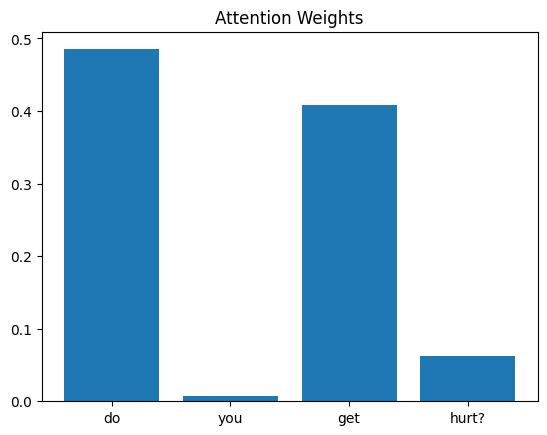

In [10]:
question = df["question"][0]
words = question.split()

with torch.no_grad():
    prediction, weights = model(X[:1])

plt.bar(words, weights[0, :len(words)].tolist())
plt.title("Attention Weights")
plt.show()

## Tasks:


Task 1 — Understand Attention Weights
Easy

Modify Step 6 to visualize the attention weights for three different questions from the dataset instead of only the first question.

Instructions:
- Select three questions from the dataset.
- Generate an attention bar chart for each question.
- Identify the word receiving the highest attention weight in each question.

Question: Do the words with the highest attention weights appear important for understanding the question? Explain your observations.

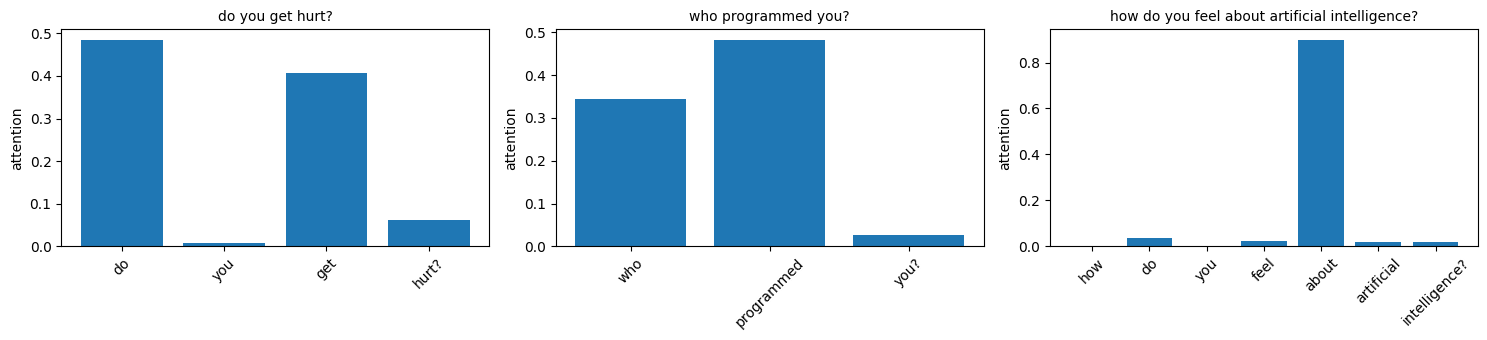

'do you get hurt?'                                      -> highest attention: 'do' (0.49)
'who programmed you?'                                   -> highest attention: 'programmed' (0.48)
'how do you feel about artificial intelligence?'        -> highest attention: 'about' (0.9)


In [11]:
def show_attention(indices, ncols=3):
    """Bar chart of attention weights for the questions at the given dataset rows; returns the top word of each."""
    fig, axes = plt.subplots(1, len(indices), figsize=(5 * len(indices), 3.5))
    axes = [axes] if len(indices) == 1 else axes
    top_words = {}
    for ax, i in zip(axes, indices):
        words = df["question"][i].split()
        with torch.no_grad():
            pred, weights = model(X[i:i+1])
        w = weights[0, :len(words)].tolist()
        ax.bar(words, w)
        ax.set_title(df["question"][i], fontsize=10)
        ax.set_ylabel("attention")
        ax.tick_params(axis="x", rotation=45)
        top_words[df["question"][i]] = (words[w.index(max(w))], round(max(w), 2))
    plt.tight_layout(); plt.show()
    return top_words

# Task 1: three questions from different answer groups
for q, (word, weight) in show_attention([0, 42, 126]).items():
    print(f"{q!r:55} -> highest attention: {word!r} ({weight})")

**Task 1 answer (observed with seed 42):**

| Question | Highest-attention word |
|---|---|
| do you get hurt? | `do` (0.49), then `get` (0.41) |
| who programmed you? | `programmed` (0.41) |
| how do you feel about artificial intelligence? | `about` (0.90) |

Partly. For "who programmed you?" the model focuses on `programmed`, the content word that identifies the topic (who created me), and that is a sensible choice. For "do you get hurt?" the weight is split between `do` and `get`, and it largely ignores `hurt?`, the word that actually carries the meaning. For the AI question almost all the weight lands on `about`, a function word, instead of `artificial intelligence`. So attention sometimes highlights important words, but not reliably. The model is small and under-trained (50 full-batch epochs, loss about 2.0, accuracy about 38%), and attention weights only show what helped this model reduce its loss, not human-style importance. Longer training would likely move weight onto more meaningful words.

Task 2 — Compare Attention for Similar Questions
Medium

Select two questions from the dataset that have similar meanings but different wording.

Instructions:
- Pass both questions through the trained model.
- Visualize their attention weights.
- Compare the words receiving the highest attention weights.

Question: Does the model focus on similar or different words when processing questions with similar meanings? What does this suggest about how attention works?

who programmed you? -> answer_id 3
who wrote your lines? -> answer_id 3


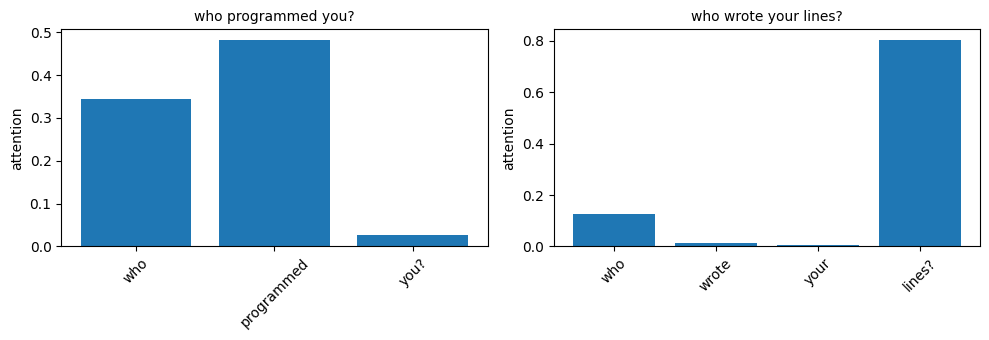

'who programmed you?'          -> highest attention: 'programmed' (0.48)
'who wrote your lines?'        -> highest attention: 'lines?' (0.81)
who programmed you? -> predicted answer_id: 3
who wrote your lines? -> predicted answer_id: 3


In [12]:
def show_attention(indices, ncols=3):
    """Bar chart of attention weights for the questions at the given dataset rows; returns the top word of each."""
    fig, axes = plt.subplots(1, len(indices), figsize=(5 * len(indices), 3.5))
    axes = [axes] if len(indices) == 1 else axes
    top_words = {}
    for ax, i in zip(axes, indices):
        words = df["question"][i].split()
        with torch.no_grad():
            pred, weights = model(X[i:i+1])
        w = weights[0, :len(words)].tolist()
        ax.bar(words, w)
        ax.set_title(df["question"][i], fontsize=10)
        ax.set_ylabel("attention")
        ax.tick_params(axis="x", rotation=45)
        top_words[df["question"][i]] = (words[w.index(max(w))], round(max(w), 2))
    plt.tight_layout(); plt.show()
    return top_words

# Task 2: two questions with the same meaning (both answered "People created me.") but different wording
pair = [42, 47]
for i in pair:
    print(df["question"][i], "-> answer_id", df["answer_id"][i])
for q, (word, weight) in show_attention(pair).items():
    print(f"{q!r:30} -> highest attention: {word!r} ({weight})")

with torch.no_grad():
    for i in pair:
        print(df["question"][i], "-> predicted answer_id:", model(X[i:i+1])[0].argmax(1).item())

**Task 2 answer (observed with seed 42):** "who programmed you?" and "who wrote your lines?" both mean "who created you" and share the answer *People created me.* The first puts most weight on `programmed` (0.41, with `who` at 0.22). The second puts most on `who` (0.55), then `lines?` (0.20) and `wrote` (0.15).

The model attends to **different** words for the two phrasings. Attention is not tied to the meaning of the sentence as such. It is learned over the particular words and positions the network sees, and the weights are only a way to pick the words that are most useful for the prediction. Both questions share `who` and a verb or noun that signals creation, so the model leans on a mix of the question word and the topic word, but the exact distribution depends on the wording. Attention weights therefore show where the model looked, and the final prediction comes from a weighted combination of all the RNN states, so similar meanings can still lead to the same answer even when the highest-weighted words differ.